In [1]:
import numpy as np
import pandas as pd
RSEED = 50

In [2]:
# Load data and remove unused text columns.
from pathlib import Path
data_path = Path("train.csv")
if not data_path.exists():
    data_path = Path("titanic/train.csv")
titanic_raw = pd.read_csv(data_path)
titanic_data = titanic_raw.copy()
titanic_data = titanic_data.drop(columns=["Name", "Ticket", "Cabin"])
# Fixed binary coding does not learn any statistics from the data.
sex_encoding = {"male": 0, "female": 1}
titanic_data["Sex"] = titanic_data["Sex"].map(sex_encoding)
assert titanic_data["Sex"].notna().all(), "Sex must be recorded as male or female."
# Keep missing values for imputation inside each training fold.
titanic_data.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Sex              0
Age            177
SibSp            0
Parch            0
Fare             0
Embarked         2
dtype: int64

In [3]:
# Train Test Split 
from sklearn.model_selection import train_test_split
# 80/20 train-test split using RSEED
train_df, test_df = train_test_split(titanic_data, test_size=0.2, random_state=RSEED)

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")

Train shape: (712, 9)
Test shape: (179, 9)


In [4]:
# Shared feature selection and preprocessing for all models.
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

feature_cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
numeric_cols = ["Age", "SibSp", "Parch", "Fare"]
binary_cols = ["Sex"]
categorical_cols = ["Pclass", "Embarked"]

X_train = train_df[feature_cols].copy()
y_train = train_df["Survived"].copy()
X_test = test_df[feature_cols].copy()
y_test = test_df["Survived"].copy()

shared_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_cols),
    ("binary", "passthrough", binary_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])


def make_model_pipeline(model):
    """Give each model its own preprocessing, fitted inside each training fold."""
    return Pipeline([
        ("preprocess", clone(shared_preprocessor)),
        ("model", clone(model)),
    ])


In [5]:
from sklearn.model_selection import StratifiedKFold
# 5-fold cross-validation with shuffling and RSEED
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RSEED)
cv_splits = list(skf.split(X_train, y_train))
for fold, (train_idx, val_idx) in enumerate(cv_splits, 1):
    fold_train = train_df.iloc[train_idx]
    fold_val = train_df.iloc[val_idx]
    print(f"Fold {fold}: Train size = {len(fold_train)}, Val size = {len(fold_val)}")

Fold 1: Train size = 569, Val size = 143
Fold 2: Train size = 569, Val size = 143
Fold 3: Train size = 570, Val size = 142
Fold 4: Train size = 570, Val size = 142
Fold 5: Train size = 570, Val size = 142


In [6]:
# Descriptive analysis of the original labeled data.
from html import escape
from IPython.display import display

eda_data = titanic_raw.copy()
eda_data["Sex"] = eda_data["Sex"].map(sex_encoding)
eda_n = len(eda_data)
eda_survivors = int(eda_data["Survived"].sum())
eda_overview = pd.DataFrame([{
    "Passengers": eda_n, "Survivors": eda_survivors,
    "Non-survivors": eda_n - eda_survivors,
    "Survival rate (%)": 100 * eda_survivors / eda_n,
}])
display(eda_overview.style.hide(axis="index").format({"Survival rate (%)": "{:.1f}"}))

eda_groups = {
    "Sex": [("0 (male)", eda_data.Sex == 0), ("1 (female)", eda_data.Sex == 1)],
    "Pclass": [(f"{level}{suffix} class", eda_data.Pclass == level)
               for level, suffix in [(1, "st"), (2, "nd"), (3, "rd")]],
    "Age": [
        ("<12 years", eda_data.Age < 12),
        ("12 to <18 years", eda_data.Age.ge(12) & eda_data.Age.lt(18)),
        ("18 to <40 years", eda_data.Age.ge(18) & eda_data.Age.lt(40)),
        ("40 to <60 years", eda_data.Age.ge(40) & eda_data.Age.lt(60)),
        ("60+ years", eda_data.Age >= 60),
        ("Missing", eda_data.Age.isna()),
    ],
    "Fare": [
        ("<=10", eda_data.Fare <= 10),
        (">10 to 30", eda_data.Fare.gt(10) & eda_data.Fare.le(30)),
        (">30 to 100", eda_data.Fare.gt(30) & eda_data.Fare.le(100)),
        (">100", eda_data.Fare > 100),
    ],
    "SibSp": [("0", eda_data.SibSp == 0), ("1", eda_data.SibSp == 1),
              ("2", eda_data.SibSp == 2), ("3+", eda_data.SibSp >= 3)],
    "Parch": [("0", eda_data.Parch == 0), ("1", eda_data.Parch == 1),
              ("2", eda_data.Parch == 2), ("3+", eda_data.Parch >= 3)],
    "Embarked": [("Cherbourg (C)", eda_data.Embarked == "C"),
                 ("Queenstown (Q)", eda_data.Embarked == "Q"),
                 ("Southampton (S)", eda_data.Embarked == "S"),
                 ("Missing", eda_data.Embarked.isna())],
}
eda_group_rows, eda_summary_rows = [], []
for eda_feature, eda_definitions in eda_groups.items():
    eda_parts = []
    for eda_label, eda_mask in eda_definitions:
        eda_count = int(eda_mask.sum())
        eda_saved = int(eda_data.loc[eda_mask, "Survived"].sum())
        eda_rate = eda_saved / eda_count if eda_count else np.nan
        eda_group_rows.append({
            "Variable": eda_feature, "Group": eda_label,
            "Passengers": eda_count, "Survivors": eda_saved,
            "Survival rate (%)": 100 * eda_rate,
            "Share of all passengers (%)": 100 * eda_count / eda_n,
            "Share of survivors (%)": 100 * eda_saved / eda_survivors,
        })
        if eda_label != "Missing":
            eda_parts.append(f"{escape(eda_label)}: <strong>{eda_rate:.1%}</strong> (n={eda_count})")
    eda_summary_rows.append({"Variable": eda_feature, "Observed survival rates": "; ".join(eda_parts)})

eda_group_details = pd.DataFrame(eda_group_rows)
eda_survival_summary = pd.DataFrame(eda_summary_rows)
display(
    eda_survival_summary.style.hide(axis="index")
    .set_caption("Observed survival rates and group sizes in the original data")
    .set_table_attributes('style="border-collapse:collapse; width:100%; max-width:1100px;"')
    .set_table_styles([
        {"selector": "caption", "props": [("text-align", "left"), ("caption-side", "top"), ("padding", "10px 0")]},
        {"selector": "th", "props": [("text-align", "left"), ("padding", "10px 12px"), ("border-bottom", "2px solid #d9dee3")]},
        {"selector": "td", "props": [("text-align", "left"), ("vertical-align", "top"), ("padding", "11px 12px"), ("line-height", "1.7"), ("border-bottom", "1px solid #e6e9ed")]},
        {"selector": "td.col0", "props": [("font-weight", "600"), ("width", "100px")]},
    ])
)

display(eda_group_details.style.hide(axis="index").format({
    "Survival rate (%)": "{:.1f}", "Share of all passengers (%)": "{:.1f}",
    "Share of survivors (%)": "{:.1f}",
}).set_caption("Detailed group counts and composition; missing values remain unfilled"))


Passengers,Survivors,Non-survivors,Survival rate (%)
891,342,549,38.4


Variable,Observed survival rates
Sex,0 (male): 18.9% (n=577); 1 (female): 74.2% (n=314)
Pclass,1st class: 63.0% (n=216); 2nd class: 47.3% (n=184); 3rd class: 24.2% (n=491)
Age,<12 years: 57.4% (n=68); 12 to <18 years: 48.9% (n=45); 18 to <40 years: 38.4% (n=438); 40 to <60 years: 39.4% (n=137); 60+ years: 26.9% (n=26)
Fare,<=10: 19.9% (n=336); >10 to 30: 43.3% (n=321); >30 to 100: 53.6% (n=181); >100: 73.6% (n=53)
SibSp,0: 34.5% (n=608); 1: 53.6% (n=209); 2: 46.4% (n=28); 3+: 15.2% (n=46)
Parch,0: 34.4% (n=678); 1: 55.1% (n=118); 2: 50.0% (n=80); 3+: 26.7% (n=15)
Embarked,Cherbourg (C): 55.4% (n=168); Queenstown (Q): 39.0% (n=77); Southampton (S): 33.7% (n=644)


Variable,Group,Passengers,Survivors,Survival rate (%),Share of all passengers (%),Share of survivors (%)
Sex,0 (male),577,109,18.9,64.8,31.9
Sex,1 (female),314,233,74.2,35.2,68.1
Pclass,1st class,216,136,63.0,24.2,39.8
Pclass,2nd class,184,87,47.3,20.7,25.4
Pclass,3rd class,491,119,24.2,55.1,34.8
Age,<12 years,68,39,57.4,7.6,11.4
Age,12 to <18 years,45,22,48.9,5.1,6.4
Age,18 to <40 years,438,168,38.4,49.2,49.1
Age,40 to <60 years,137,54,39.4,15.4,15.8
Age,60+ years,26,7,26.9,2.9,2.0



Top 5 hyperparameter settings, ranked by validation ROC AUC


,Trees,Max depth,Min leaf size,Max features,CV Accuracy,CV F1,CV ROC AUC,CV AUC SD
0,200,8,3,6,0.8370,0.7530,0.8816,0.0302
1,400,8,1,4,0.8398,0.7563,0.8814,0.0292
2,200,8,2,6,0.8384,0.7567,0.8812,0.0309
3,400,8,2,3,0.8398,0.7508,0.8812,0.0297
4,400,8,2,6,0.8384,0.7573,0.8812,0.0307



Selected hyperparameters from 5-fold CV


Trees,Max depth,Min leaf size,Max features
200,8,3,6



Test-set classification counts


,TP,FP,TN,FN
Random Forest,50,8,93,28



Held-out test results


,Test N,Accuracy,Precision,Recall,F1 Score,ROC AUC
Random Forest,179,0.7989,0.8621,0.641,0.7353,0.8508


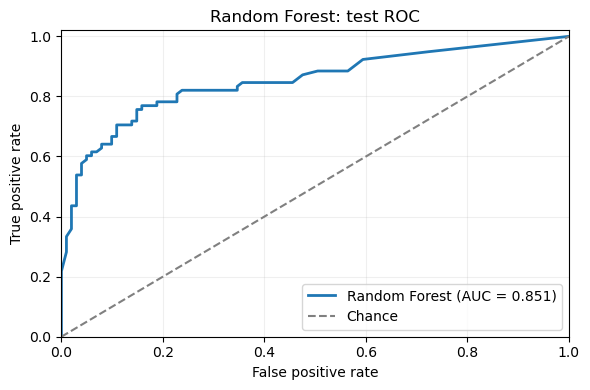


Permutation importance on the held-out test set


,Feature,Mean AUC decrease,Shuffle SD
0,Sex,0.2214,0.0376
1,Pclass,0.0412,0.0132
2,Age,0.0380,0.0178
3,Fare,0.0232,0.0135
4,SibSp,0.0075,0.0036
5,Embarked,0.0014,0.0081
6,Parch,0.0012,0.0057


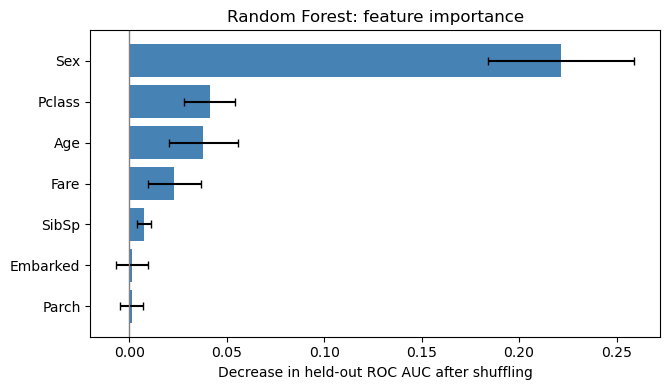

In [7]:
# Random Forest: reuse the existing split, folds, and labels.
# Run the notebook from the first cell; all training uses scikit-learn.
# Aggregate individual tree predictions by majority vote.
from IPython.display import display
import matplotlib.pyplot as plt
from scipy.stats import mode
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    confusion_matrix, accuracy_score, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, ParameterGrid



def rf_vote_outputs(fitted_pipeline, X):
    """Return majority-vote classes and survival vote shares; ties select 0."""
    X_encoded = fitted_pipeline.named_steps["preprocess"].transform(X)
    forest = fitted_pipeline.named_steps["model"]
    if not np.array_equal(forest.classes_, [0, 1]):
        raise ValueError("This analysis expects Titanic labels 0 and 1.")
    tree_votes = np.column_stack([
        tree.predict(X_encoded) for tree in forest.estimators_
    ])
    predictions = mode(tree_votes, axis=1, keepdims=False).mode.astype(int)
    survival_vote_share = np.mean(tree_votes == 1, axis=1)
    return predictions, survival_vote_share


def rf_score_metrics(fitted_pipeline, X, y):
    """Score majority-vote predictions for cross-validation."""
    predictions, vote_share = rf_vote_outputs(fitted_pipeline, X)
    return {
        "accuracy": accuracy_score(y, predictions),
        "f1": f1_score(y, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y, vote_share),
    }


def rf_vote_auc(fitted_pipeline, X, y):
    """Use the identical vote-share ROC AUC for permutation importance."""
    _, vote_share = rf_vote_outputs(fitted_pipeline, X)
    return roc_auc_score(y, vote_share)


# Reuse the common data, preprocessing rules, and validation folds.
rf_features = feature_cols.copy()
rf_numeric = numeric_cols.copy()
rf_binary = binary_cols.copy()
rf_categorical = categorical_cols.copy()
X_rf_train = X_train.copy()
y_rf_train = y_train.copy()
rf_cv_splits = cv_splits
rf_preprocessor = shared_preprocessor
assert len(rf_cv_splits) == 5
assert set(train_df["PassengerId"]).isdisjoint(test_df["PassengerId"])

rf_pipeline = make_model_pipeline(RandomForestClassifier(
    bootstrap=True, criterion="gini", random_state=RSEED, n_jobs=1,
))

# 160 settings x 5 folds. ROC AUC is the pre-specified selection metric.
# max_features is an integer count of encoded columns per split.
# Compare smaller candidate subsets of the 11 encoded input columns.
# Parallelize the search, not both the search and each forest.
rf_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [4, 6, 8, 12, None],
    "model__min_samples_leaf": [1, 2, 3, 5],
    "model__max_features": [3, 4, 6, 8],
}
rf_search = GridSearchCV(
    rf_pipeline,
    param_grid=rf_param_grid,
    scoring=rf_score_metrics,
    refit="roc_auc",
    cv=rf_cv_splits,
    n_jobs=4,
    return_train_score=True,
    error_score="raise",
)
rf_n_settings = len(ParameterGrid(rf_param_grid))
rf_search.fit(X_rf_train, y_rf_train)
rf_best_model = rf_search.best_estimator_  # Already refitted on all training rows.
rf_best_params = {
    name.replace("model__", ""): value
    for name, value in rf_search.best_params_.items()
}

# These CV scores were also used for tuning; they are not an independent
# estimate of the selected model's performance. Use the held-out test below.
rf_cv_results = pd.DataFrame(rf_search.cv_results_)
rf_tuning_table = rf_cv_results.sort_values("rank_test_roc_auc")[[
    "param_model__n_estimators", "param_model__max_depth",
    "param_model__min_samples_leaf", "param_model__max_features",
    "mean_test_accuracy", "mean_test_f1", "mean_test_roc_auc",
    "std_test_roc_auc",
]].rename(columns={
    "param_model__n_estimators": "Trees",
    "param_model__max_depth": "Max depth",
    "param_model__min_samples_leaf": "Min leaf size",
    "param_model__max_features": "Max features",
    "mean_test_accuracy": "CV Accuracy",
    "mean_test_f1": "CV F1",
    "mean_test_roc_auc": "CV ROC AUC",
    "std_test_roc_auc": "CV AUC SD",
})
print("\nTop 5 hyperparameter settings, ranked by validation ROC AUC")
display(rf_tuning_table.head(5).round(4).reset_index(drop=True))


rf_selected_params = pd.DataFrame([{
    "Trees": rf_best_params["n_estimators"],
    "Max depth": "None" if rf_best_params["max_depth"] is None else rf_best_params["max_depth"],
    "Min leaf size": rf_best_params["min_samples_leaf"],
    "Max features": rf_best_params["max_features"],
}])
print("\nSelected hyperparameters from 5-fold CV")
display(rf_selected_params.style.hide(axis="index").format({"Max features": "{:d}"}))
rf_encoded_feature_count = rf_best_model.named_steps["model"].n_features_in_

# The model and hyperparameters are now fixed. Evaluate on the held-out 20%.
# ROC AUC uses the fraction of trees voting for survival as its ranking score.
X_rf_test = X_test.copy()
y_rf_test = y_test.copy()
# Compute majority-vote labels and survival vote shares.
rf_test_predictions, rf_test_vote_shares = rf_vote_outputs(rf_best_model, X_rf_test)
# Survived (1) is the positive class.
rf_tn, rf_fp, rf_fn, rf_tp = confusion_matrix(
    y_rf_test, rf_test_predictions, labels=[0, 1],
).ravel()
rf_classification_counts = pd.DataFrame([{
    "Model": "Random Forest",
    "TP": int(rf_tp), "FP": int(rf_fp),
    "TN": int(rf_tn), "FN": int(rf_fn),
}]).set_index("Model").rename_axis(None)
print("\nTest-set classification counts")
display(rf_classification_counts)

rf_test_results = pd.DataFrame([{
    "Model": "Random Forest",
    "Test N": len(y_rf_test),
    "Accuracy": accuracy_score(y_rf_test, rf_test_predictions),
    "Precision": precision_score(y_rf_test, rf_test_predictions, zero_division=0),
    "Recall": recall_score(y_rf_test, rf_test_predictions, zero_division=0),
    "F1 Score": f1_score(y_rf_test, rf_test_predictions, zero_division=0),
    "ROC AUC": roc_auc_score(y_rf_test, rf_test_vote_shares),
}]).set_index("Model").rename_axis(None)
print("\nHeld-out test results")
display(rf_test_results.round(4))

rf_fpr, rf_tpr, _ = roc_curve(y_rf_test, rf_test_vote_shares)
rf_fig, rf_ax = plt.subplots(figsize=(6, 4))
rf_ax.plot(
    rf_fpr, rf_tpr, color="tab:blue", linewidth=2,
    label=f"Random Forest (AUC = {rf_test_results.loc['Random Forest', 'ROC AUC']:.3f})",
)
rf_ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
rf_ax.set(
    xlabel="False positive rate", ylabel="True positive rate",
    title="Random Forest: test ROC", xlim=(0, 1), ylim=(0, 1.02),
)
rf_ax.legend(loc="lower right")
rf_ax.grid(alpha=0.2)
rf_fig.tight_layout()
plt.show()

# Shuffle one original feature at a time, before one-hot encoding.
# This gives one importance value per original variable, including Embarked.
# Test-set importance is for interpretation only: do not use it to retune
# the model, drop features, or choose a prediction threshold on this test set.
rf_permutation = permutation_importance(
    rf_best_model, X_rf_test, y_rf_test,
    scoring=rf_vote_auc, n_repeats=20, random_state=RSEED, n_jobs=2,
)
rf_importance = pd.DataFrame({
    "Feature": rf_features,
    "Mean AUC decrease": rf_permutation.importances_mean,
    "Shuffle SD": rf_permutation.importances_std,
}).sort_values("Mean AUC decrease", ascending=False).reset_index(drop=True)
print("\nPermutation importance on the held-out test set")
display(rf_importance.round(4))

rf_importance_plot = rf_importance.sort_values("Mean AUC decrease")
rf_importance_fig, rf_importance_ax = plt.subplots(figsize=(6.8, 4))
rf_importance_ax.barh(
    rf_importance_plot["Feature"], rf_importance_plot["Mean AUC decrease"],
    xerr=rf_importance_plot["Shuffle SD"], color="steelblue", capsize=3,
)
rf_importance_ax.axvline(0, color="gray", linewidth=1)
rf_importance_ax.set(
    xlabel="Decrease in held-out ROC AUC after shuffling",
    title="Random Forest: feature importance",
)
rf_importance_fig.tight_layout()
plt.show()


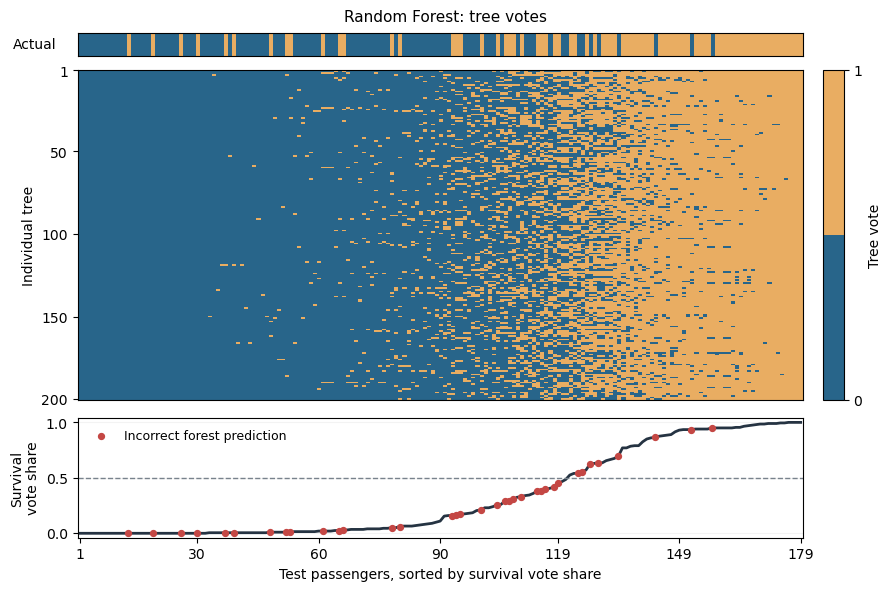

Vote group,Passengers,Errors,Accuracy (%)
Vote share 0.4 to 0.6,10,4,60.0
"Other, below 90% agreement",48,16,66.7
At least 90% agreement,121,16,86.8


Sex,Pclass,Age,Actual,Predicted,Survival vote share
1,1,2,0,1,0.9350
0,3,25,1,0,0.0000


In [8]:
# Show individual tree votes and the resulting forest vote share.
from matplotlib.colors import ListedColormap

rf_diag_encoded_test = rf_best_model.named_steps["preprocess"].transform(X_rf_test)
rf_diag_tree_votes = np.column_stack([
    tree.predict(rf_diag_encoded_test)
    for tree in rf_best_model.named_steps["model"].estimators_
])
rf_diag_order = np.argsort(rf_test_vote_shares, kind="mergesort")
rf_diag_sorted_scores = rf_test_vote_shares[rf_diag_order]
rf_diag_sorted_truth = y_rf_test.to_numpy()[rf_diag_order]
rf_diag_sorted_wrong = (
    rf_test_predictions[rf_diag_order] != rf_diag_sorted_truth
)
rf_diag_vote_colors = ListedColormap(["#28658a", "#e9ad62"])
rf_diag_vote_fig = plt.figure(figsize=(8.8, 5.8), constrained_layout=True)
rf_diag_vote_grid = rf_diag_vote_fig.add_gridspec(
    3, 2, height_ratios=[0.28, 4, 1.45], width_ratios=[35, 1],
)
rf_diag_truth_ax = rf_diag_vote_fig.add_subplot(rf_diag_vote_grid[0, 0])
rf_diag_votes_ax = rf_diag_vote_fig.add_subplot(rf_diag_vote_grid[1, 0], sharex=rf_diag_truth_ax)
rf_diag_score_ax = rf_diag_vote_fig.add_subplot(rf_diag_vote_grid[2, 0], sharex=rf_diag_truth_ax)
rf_diag_cbar_ax = rf_diag_vote_fig.add_subplot(rf_diag_vote_grid[1, 1])
rf_diag_truth_ax.imshow(rf_diag_sorted_truth[None, :], aspect="auto",
                        cmap=rf_diag_vote_colors, vmin=0, vmax=1, interpolation="nearest")
rf_diag_truth_ax.set_ylabel("Actual", rotation=0, ha="right", va="center", labelpad=12)
rf_diag_truth_ax.set_yticks([])
rf_diag_truth_ax.tick_params(axis="x", bottom=False, labelbottom=False)
rf_diag_vote_image = rf_diag_votes_ax.imshow(
    rf_diag_tree_votes[rf_diag_order].T, aspect="auto", interpolation="nearest",
    cmap=rf_diag_vote_colors, vmin=0, vmax=1, origin="upper",
)
rf_diag_votes_ax.set_ylabel("Individual tree")
rf_diag_n_trees = rf_diag_tree_votes.shape[1]
rf_diag_tree_ticks = np.linspace(0, rf_diag_n_trees - 1, 5).astype(int)
rf_diag_votes_ax.set_yticks(rf_diag_tree_ticks)
rf_diag_votes_ax.set_yticklabels(rf_diag_tree_ticks + 1)
rf_diag_votes_ax.tick_params(axis="x", bottom=False, labelbottom=False)
rf_diag_vote_fig.colorbar(rf_diag_vote_image, cax=rf_diag_cbar_ax, ticks=[0, 1], label="Tree vote")
rf_diag_x = np.arange(len(rf_diag_order))
rf_diag_score_ax.plot(rf_diag_x, rf_diag_sorted_scores, color="#253342", linewidth=2)
rf_diag_score_ax.scatter(
    rf_diag_x[rf_diag_sorted_wrong], rf_diag_sorted_scores[rf_diag_sorted_wrong],
    color="#c44744", s=18, zorder=3, label="Incorrect forest prediction",
)
rf_diag_score_ax.axhline(0.5, color="#78828c", linestyle="--", linewidth=1)
rf_diag_score_ax.set_ylim(-0.04, 1.04)
rf_diag_score_ax.set_ylabel("Survival\nvote share")
rf_diag_score_ax.set_xlabel("Test passengers, sorted by survival vote share")
rf_diag_x_ticks = np.linspace(0, len(rf_diag_order) - 1, 7).astype(int)
rf_diag_score_ax.set_xticks(rf_diag_x_ticks)
rf_diag_score_ax.set_xticklabels(rf_diag_x_ticks + 1)
rf_diag_score_ax.legend(loc="upper left", frameon=False, fontsize=9)
rf_diag_score_ax.grid(axis="y", alpha=0.15)
rf_diag_vote_fig.suptitle("Random Forest: tree votes", fontsize=11)
plt.show()


# Relate vote agreement to observed test errors.
rf_error_analysis = X_rf_test.copy()
rf_error_analysis["Actual"] = y_rf_test.to_numpy()
rf_error_analysis["Predicted"] = rf_test_predictions
rf_error_analysis["Survival vote share"] = rf_test_vote_shares
rf_error_analysis["Incorrect"] = rf_test_predictions != y_rf_test.to_numpy()
rf_near_threshold = rf_error_analysis["Survival vote share"].between(0.4, 0.6, inclusive="both")
rf_high_agreement = np.maximum(rf_test_vote_shares, 1 - rf_test_vote_shares) >= 0.9
rf_other_agreement = ~(rf_near_threshold.to_numpy() | rf_high_agreement)
rf_agreement_rows = []
for rf_group_label, rf_group_mask in [
    ("Vote share 0.4 to 0.6", rf_near_threshold),
    ("Other, below 90% agreement", rf_other_agreement),
    ("At least 90% agreement", rf_high_agreement),
]:
    rf_group_n = int(np.sum(rf_group_mask))
    rf_group_errors = int(rf_error_analysis.loc[rf_group_mask, "Incorrect"].sum())
    rf_agreement_rows.append({
        "Vote group": rf_group_label, "Passengers": rf_group_n,
        "Errors": rf_group_errors,
        "Accuracy (%)": 100 * (rf_group_n - rf_group_errors) / rf_group_n,
    })
rf_agreement_summary = pd.DataFrame(rf_agreement_rows)
display(rf_agreement_summary.style.hide(axis="index").format({"Accuracy (%)": "{:.1f}"})
        .set_caption("Observed test accuracy by vote agreement; these groups are not used for tuning"))

# Select a child with a recorded age and a contrasting adult error.
rf_false_positive_examples = rf_error_analysis.loc[
    (rf_error_analysis.Actual == 0) & (rf_error_analysis.Predicted == 1)
    & rf_error_analysis.Age.lt(12)
].sort_values("Survival vote share", ascending=False).head(1)
rf_false_negative_examples = rf_error_analysis.loc[
    (rf_error_analysis.Actual == 1) & (rf_error_analysis.Predicted == 0)
    & rf_error_analysis.Age.notna()
].sort_values("Survival vote share").head(1)
rf_illustrative_errors = pd.concat([rf_false_positive_examples, rf_false_negative_examples])[
    ["Sex", "Pclass", "Age", "Actual", "Predicted", "Survival vote share"]
]
display(rf_illustrative_errors.style.hide(axis="index").format({"Age": "{:.0f}", "Survival vote share": "{:.4f}"})
        .set_caption("Two illustrative high-agreement errors; Actual and Predicted use 1 = survived"))
